<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Week 1 — Python, NumPy, pandas & Matplotlib Refresher</div>
</div>

<div style="background-color:#38614A;color:#ffffff;padding:10px 16px;border-radius:4px;font-family:Arial, Helvetica, sans-serif;font-weight:700;margin-top:10px;">
Worked solutions: try each exercise yourself first, then compare.
</div>

#### This notebook revises the Python skills introduced in PHYS281 that the rest of this module builds on.
***

## <span style="color:#B5121B">How to use this notebook</span>
This notebook revises material from PHYS281. Run every cell, change the values and see what breaks. There are short exercises after most sections: do them as you go.
***

## NumPy revision

In [1]:
import numpy as np

# Arrays behave like vectors: operations apply elementwise, without an explicit loop
x = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y = np.array([10.0, 20.0, 30.0, 40.0, 50.0])
print("x + y      =", x + y)
print("x * 2      =", x * 2)
print("mean(x)    =", x.mean())
print("std(x)     =", x.std())

x + y      = [11. 22. 33. 44. 55.]
x * 2      = [ 2.  4.  6.  8. 10.]
mean(x)    = 3.0
std(x)     = 1.4142135623730951


**Vectorisation matters.** A NumPy array operation runs as compiled C code rather than as a Python loop. Compare the two for the same calculation:

In [2]:
import timeit

n = 2_000_000
data = np.random.default_rng(0).uniform(0, 1, size=n)

def loop_version():
    total = 0.0
    for v in data:
        total += v ** 2
    return total

def vectorised_version():
    return (data ** 2).sum()

# Take the best of a few repeats - a single timing is noisy, especially
# the very first call, which pays a one-off warm-up cost unrelated to the
# calculation itself.
t_loop = min(timeit.repeat(loop_version, number=1, repeat=3))
t_vec = min(timeit.repeat(vectorised_version, number=1, repeat=3))

print(f"Python loop : {t_loop:.4f} s   (result={loop_version():.4f})")
print(f"Vectorised  : {t_vec:.5f} s   (result={vectorised_version():.4f})")
print(f"Speed-up    : {t_loop / t_vec:.0f}x")

Python loop : 0.3442 s   (result=666970.9782)
Vectorised  : 0.00343 s   (result=666970.9782)
Speed-up    : 100x


### From loops to linear algebra

`(data ** 2).sum()` isn't just a faster loop: it describes the calculation in a different way. Compare a dot product computed both ways:

In [3]:
a = np.array([1.0, 2.0, 3.0, 4.0])
b = np.array([5.0, 6.0, 7.0, 8.0])

# As a loop - exactly what you'd write in plain Python
total = 0.0
for i in range(len(a)):
    total += a[i] * b[i]
print("loop result :", total)

# As linear algebra: a dot product
print("np.dot      :", np.dot(a, b))
print("@ operator  :", a @ b)

loop result : 70.0
np.dot      : 70.0
@ operator  : 70.0


The loop `for i in range(len(a)): total += a[i] * b[i]`, the expression $\mathbf{a}\cdot\mathbf{b} = \sum_i a_i b_i$ and `a @ b` are the *same calculation*. `@` (and `np.dot`) performs the loop above in compiled code.

The same holds for matrices. A matrix-vector multiplication is a loop of dot products, one per row:

In [4]:
# A 3x4 matrix (e.g. three different weighted combinations of four inputs)
M = np.array([
    [1.0, 0.0, 2.0, 1.0],
    [0.0, 1.0, 0.0, 3.0],
    [2.0, 1.0, 1.0, 0.0],
])
v = np.array([1.0, 2.0, 3.0, 4.0])

# As nested loops
result_loop = np.zeros(M.shape[0])
for i in range(M.shape[0]):          # one dot product per row...
    row_total = 0.0
    for j in range(M.shape[1]):      # ...computed as a loop over columns
        row_total += M[i, j] * v[j]
    result_loop[i] = row_total
print("loop result   :", result_loop)

# As linear algebra
print("matrix result :", M @ v)

loop result   : [11. 14.  7.]
matrix result : [11. 14.  7.]


Two nested loops (rows, then columns) *are* a matrix-vector multiplication. Replacing a loop with an array operation means rewriting the calculation as linear algebra.

> **Quick check:** without running it, what shape would `result_loop` be if `M` were 5×4 instead of 3×4? How does `v @ M.T` compare with `M @ v`: same numbers, a different shape, or something else? Run it to check your answer.

<span style="color:#38614A">**Answer.**</span> `result_loop` has one entry per **row** of `M`, so a 5×4 matrix gives shape `(5,)`. `v @ M.T` gives the same numbers and shape as `M @ v`, since $(\mathbf{v}^T M^T)^T = M\mathbf{v}$ and NumPy doesn't distinguish row and column vectors for 1-D arrays. `v @ M` fails: the inner dimensions (4 and 3) don't match.

In [5]:
M5 = np.vstack([M, [[1.0, 1.0, 1.0, 1.0], [0.0, 2.0, 0.0, 2.0]]])   # 5x4
print("M5 @ v shape :", (M5 @ v).shape)
print("M @ v        :", M @ v)
print("v @ M.T      :", v @ M.T)
try:
    v @ M
except ValueError as err:
    print("v @ M fails  :", err)

M5 @ v shape : (5,)
M @ v        : [11. 14.  7.]
v @ M.T      : [11. 14.  7.]
v @ M fails  : matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 4)


***
## pandas: loading and exploring data

`pandas` is built on NumPy and handles labelled, tabular data: rows and columns, like a spreadsheet, but scriptable.

In [6]:
import pandas as pd
import os

# Data: read from a local datasets/ folder if you've cloned/downloaded the
# repository, otherwise straight from GitHub (e.g. in Colab). Same file either way.
DATA_URL = "https://raw.githubusercontent.com/MatSmithAstro/phys7101_2026_resources/main/workshops/week1/datasets/"

def data_path(filename):
    local = os.path.join("datasets", filename)
    return local if os.path.exists(local) else DATA_URL + filename

df = pd.read_csv(data_path("pandas_practice_dataset.csv"))
df.head()

,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


### Selecting, slicing and masking

In [7]:
# A boolean mask selects rows matching a condition
high_calorie = df[df["Calories"] > 400]
high_calorie

,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
4,45,'2020/12/05',117,148,406.0


In [8]:
# Selecting specific columns
df[["Date", "Pulse", "Calories"]].head()

,Date,Pulse,Calories
0,'2020/12/01',110,409.1
1,'2020/12/02',117,479.0
2,'2020/12/03',103,340.0
3,'2020/12/04',109,282.4
4,'2020/12/05',117,406.0


### Grouping and aggregating

> **If you've used SQL:** `.groupby()` does the same job as `GROUP BY`, the boolean mask above (`df[df["Calories"] > 400]`) is `WHERE`, and `.merge()` is `JOIN`. The syntax differs, but the operations (group, filter, combine tables) are the same as in a database query.

In [9]:
# Mean calories burned, grouped by session duration
df.groupby("Duration")["Calories"].mean()

Duration
30     195.10000
45     291.88000
60     314.46087
450    253.30000
Name: Calories, dtype: float64

> **Quick check:** the `Maxpulse` column exists alongside `Pulse`. Compute, in one line, the mean *difference* between them (`Maxpulse - Pulse`) for each `Duration` group. Is the gap bigger for longer or shorter sessions?

In [10]:
(df["Maxpulse"] - df["Pulse"]).groupby(df["Duration"]).mean()

Duration
30     24.000000
45     32.166667
60     23.041667
450    30.000000
dtype: float64

<span style="color:#38614A">**Answer.**</span> The gap is largest for the 45-minute sessions (about 32 bpm) and about 23–24 bpm for the 30- and 60-minute sessions, so there is no clear trend with length. The 30- and 450-minute groups have one row each. Points to raise: `Duration = 450` is almost certainly a typo for 45, and one row (23 Dec) has `Maxpulse` below `Pulse`.

***
## Matplotlib basics

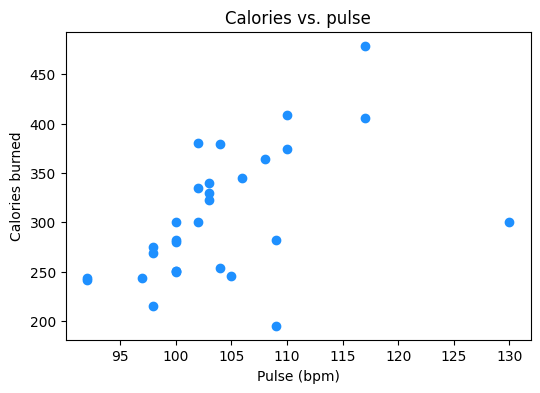

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df["Pulse"], df["Calories"], "o", color="dodgerblue")
ax.set_xlabel("Pulse (bpm)")
ax.set_ylabel("Calories burned")
ax.set_title("Calories vs. pulse")
plt.show()

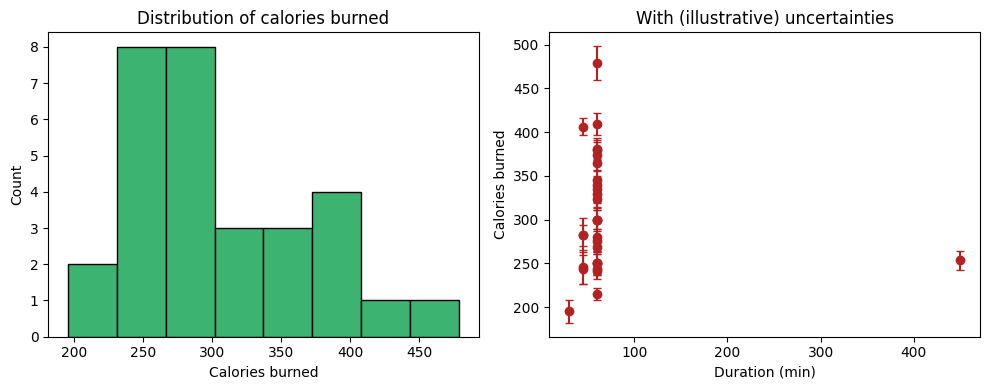

In [12]:
# A histogram, and an errorbar plot with synthetic uncertainties
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df["Calories"], bins=8, color="mediumseagreen", edgecolor="black")
axes[0].set_xlabel("Calories burned")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of calories burned")

rng = np.random.default_rng(1)
y_err = rng.uniform(5, 20, size=len(df))
axes[1].errorbar(df["Duration"], df["Calories"], yerr=y_err, fmt="o", color="firebrick", capsize=3)
axes[1].set_xlabel("Duration (min)")
axes[1].set_ylabel("Calories burned")
axes[1].set_title("With (illustrative) uncertainties")

fig.tight_layout()
plt.show()

### Saving figures

Save figures at a sensible resolution, with a tight bounding box, and in a vector format (PDF) where possible, so they stay sharp at any zoom.

Saved.


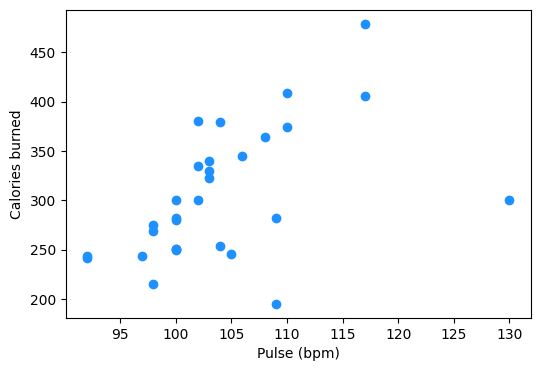

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df["Pulse"], df["Calories"], "o", color="dodgerblue")
ax.set_xlabel("Pulse (bpm)")
ax.set_ylabel("Calories burned")
fig.savefig("pulse_vs_calories.pdf", bbox_inches="tight", dpi=200)
print("Saved.")

***
## <span style="color:#FD9029">Exercises</span>

These become less prescriptive as you go; the last two are open-ended.

1. Compute the mean **and** standard deviation of `Calories` for each `Duration` group (hint: `.agg(["mean", "std"])`). Make a single, clearly labelled bar chart of the mean calories per group, with the standard deviation as error bars. Save it as a PDF.
2. Rewrite the matrix-vector multiplication from the NumPy section so that it computes `M @ v` using only `np.dot` in a loop over rows (no `@`, no nested loop). This sits between the fully looped and the fully vectorised versions.
3. The `Date` column is stored as text. Convert it to a datetime type with `pd.to_datetime`, then plot `Calories` against date as a line, with real dates on the x-axis.
   *Hint: look at the raw `Date` values first. Some are wrapped in quote marks, one uses a different format and one is missing, so `pd.to_datetime` will fail until the column is tidied. `.str.strip()` and the `format="mixed"` and `errors="coerce"` options will help.*
4. **Open-ended:** using only the tools in this notebook, find and plot one relationship in the data not shown above (e.g. does `Maxpulse` predict `Calories` better than `Pulse`?). Produce one figure and one sentence stating what you found.
***

### Solution 1: mean and standard deviation per duration group

               mean        std  count
Duration                             
30        195.10000        NaN      1
45        291.88000  66.530234      5
60        314.46087  64.302621     23
450       253.30000        NaN      1


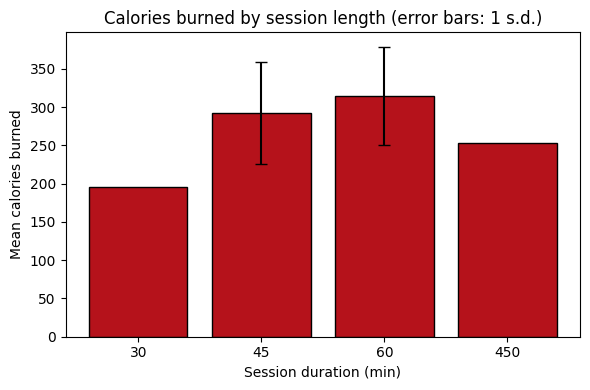

In [14]:
summary = df.groupby("Duration")["Calories"].agg(["mean", "std", "count"])
print(summary)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(summary.index.astype(str), summary["mean"], yerr=summary["std"],
       capsize=4, color="#B5121B", edgecolor="black")
ax.set_xlabel("Session duration (min)")
ax.set_ylabel("Mean calories burned")
ax.set_title("Calories burned by session length (error bars: 1 s.d.)")
fig.tight_layout()
fig.savefig("calories_by_duration.pdf", bbox_inches="tight")
plt.show()

<span style="color:#38614A">**Answer.**</span> Treating the duration as a category (`.astype(str)`) keeps the bars evenly spaced. The 30- and 450-minute groups have one session each, so their standard deviation is `NaN` (no error bar). `.mean()` skips the two missing `Calories` values; `count` shows how many were used.

### Solution 2: one `np.dot` per row

In [15]:
result_rows = np.array([np.dot(M[i], v) for i in range(M.shape[0])])
print("row-by-row np.dot :", result_rows)
print("M @ v             :", M @ v)
print("agree:", np.allclose(result_rows, M @ v))

row-by-row np.dot : [11. 14.  7.]
M @ v             : [11. 14.  7.]
agree: True


<span style="color:#38614A">**Answer.**</span> Each output element is the dot product of one row of `M` with `v`. The column loop is now done by NumPy; the row loop is still Python.

### Solution 3: dates

   Date Date_parsed
22  NaN         NaT


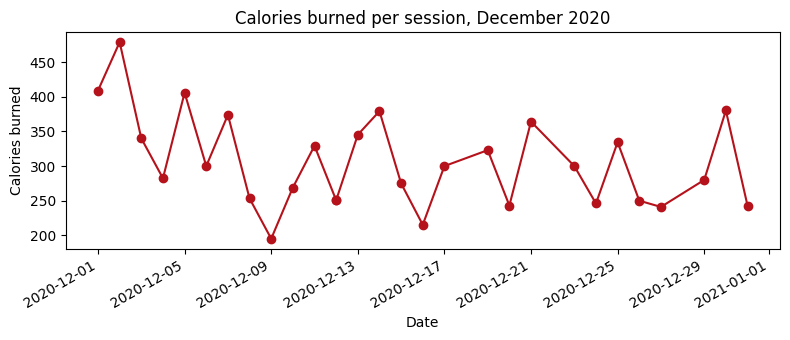

In [16]:
raw = df["Date"].astype("string").str.strip("'")          # remove the quote marks
df["Date_parsed"] = pd.to_datetime(raw, format="mixed", errors="coerce")
print(df.loc[df["Date_parsed"].isna(), ["Date", "Date_parsed"]])   # the one missing date

clean = df.dropna(subset=["Date_parsed", "Calories"]).sort_values("Date_parsed")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(clean["Date_parsed"], clean["Calories"], "o-", color="#B5121B")
ax.set_xlabel("Date")
ax.set_ylabel("Calories burned")
ax.set_title("Calories burned per session, December 2020")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

<span style="color:#38614A">**Answer.**</span> Following the hint: strip the quote marks, then `format="mixed"` handles the `20201226` entry and `errors="coerce"` turns the missing date into `NaT`, which is dropped. The 12 Dec row is duplicated, so that date appears twice.

### Solution 4 (one possible answer): does `Maxpulse` predict `Calories` better than `Pulse`?

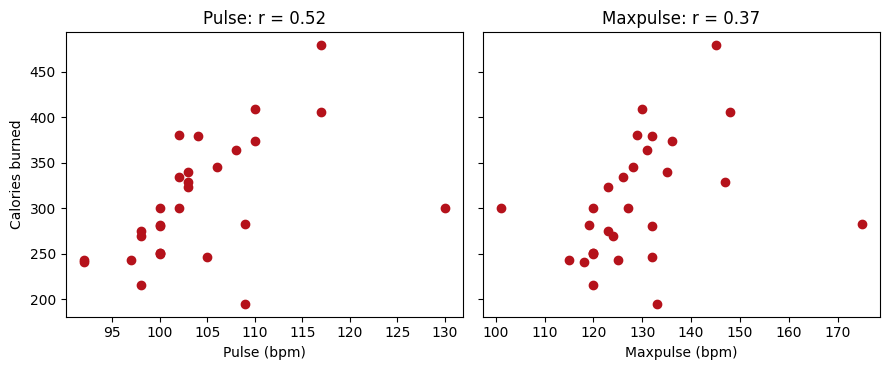

Pearson r  Pulse-Calories    = 0.52
Pearson r  Maxpulse-Calories = 0.37


In [17]:
ok = df.dropna(subset=["Calories"])
ok = ok[ok["Duration"] != 450]          # drop the obvious typo
r_pulse = ok["Pulse"].corr(ok["Calories"])
r_max = ok["Maxpulse"].corr(ok["Calories"])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, col, r in zip(axes, ["Pulse", "Maxpulse"], [r_pulse, r_max]):
    ax.scatter(ok[col], ok["Calories"], color="#B5121B")
    ax.set_xlabel(f"{col} (bpm)")
    ax.set_title(f"{col}: r = {r:.2f}")
axes[0].set_ylabel("Calories burned")
fig.tight_layout()
plt.show()
print(f"Pearson r  Pulse-Calories    = {r_pulse:.2f}")
print(f"Pearson r  Maxpulse-Calories = {r_max:.2f}")

<span style="color:#38614A">**Answer.**</span> Average pulse is the better single predictor (r ≈ 0.52 against 0.37 for maximum pulse). Any clearly labelled figure with a one-sentence, quantified claim should get full credit. A good answer also notes that ~30 rows make the correlation uncertain.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>